# Assignment 5 — Applied topic modeling and sentiment around the U.S. midterms

**Panagiotis Housos | ph2606 | FRE-GY 7871A | Fall 2026**

Information through October 8, 2026 at 16:00 New York. Model training ends August 21; assessment begins August 22. The separate six-page PDF shares this computed narrative. Raw and derived datasets are intentionally excluded from Git. See README for acquisition and the pinned contextual model.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / 'src/text_model.py').exists(), 'Run from the repository root.'
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.precision', 4)

## Recalculate from the acquired observations

Acquisition is explicit in the README and runs separately. The cell below reconstructs scores and all statistical exhibits from local caches; it does not create observations. The contextual file must match every current corpus ID. The saved outputs below contain aggregate results only.

In [2]:
from src.text_model import score_documents
from src.analysis import analyze
from src.issue_sentiment import build as issue_indices
from src.figures import build as draw_figures
assert (ROOT / 'data/processed/contextual_scores.csv').exists(), 'Run the contextual scorer after acquisition and initial text modeling.'
scored = score_documents()
calendar, market, tests = analyze()
issue_indices()
draw_figures()
summary = json.loads((ROOT / 'outputs/summary.json').read_text())
display(pd.Series(summary, name='observed_result'))
print('All indices and associations recalculated from acquired observations.')

requested_start                                                                      2026-08-01
train_end                                                                            2026-08-21
end                                                                                  2026-10-08
documents                                                         {'news': 2953, 'social': 279}
training_documents                                                                          614
model_covered                                                                              3183
topic_k                                                                                       4
calendar_days                                                                                69
market_sessions                                                                              48
test_calendar_days                                                                           48
test_market_sessions                    

All indices and associations recalculated from acquired observations.


## Question, evidence and main result

I study the November 2026 U.S. midterms as a possible market event. A Democratic sweep means Democratic control of both the House and Senate. The presidency is not on the ballot. The research asks which issues appear in election discourse, whether the tone around those issues moves with sweep prices, and whether the same tone relates to a policy-exposed equity basket.

The strongest evidence about voter priorities is the survey benchmark: the economy, the future of democracy and healthcare lead the October Pew ratings. The unsupervised text model mainly finds campaigning, Senate races, voting and political commentary. That difference matters. A ranked news feed and a technology forum show the subjects being discussed in this sample; they do not measure the electorate’s issue weights.

| Study component | Observed design |
| --- | --- |
| Information window | Aug. 1–Oct. 8, 2026; final cutoff 16:00 New York |
| Model training | Text available by Aug. 21 close; 614 eligible documents |
| Assessment period | Aug. 22–Oct. 8; 48 calendar days / 33 cash sessions |
| Aligned corpus | 2,953 news headlines + 279 HN records |
| Prediction markets | Direct joint DD contracts on Polymarket and Kalshi |
| Equities | FSLR, ENPH, RUN, GEO, CXW; UNH diagnostic only |

Over the complete window, Polymarket’s joint sweep quote rose from 44.5% to 63.5%; Kalshi moved from 45.5% to 61.5%. Yet the five-stock long-only basket returned -7.44%, compared with SPY’s +3.86%. The signed solar-long/detention-short basket returned -11.27% before financing and trading costs.

Using changes in the combined contextual RoBERTa wording index, the assessment-period same-day correlations with changes in the two contract quotes are -0.18 (Polymarket, n=44) and 0.10 (Kalshi, n=44). Its correlation with the five-stock basket minus SPY is -0.05 over 33 sessions. 1 of 40 core associations survives Holm correction: Trump, taxes and campaigning and signed beta-adjusted basket, lag 0: r=0.36, n=28, adjusted p=0.023. Independent confirmation is needed.

My investment conclusion is to use the issues and contracts for scenario monitoring, rather than place a sentiment-timing trade from this sample. The observed equity moves do not validate the simple claim that a rising sweep price automatically lifts the proposed beneficiaries.

In [3]:
print('text_filter_audit')
display(pd.read_csv(ROOT / 'outputs/text_filter_audit.csv'))

text_filter_audit


,source_type,exclusion,n
0,news,NaN,2953
1,news,after_final_information_cutoff,85
2,news,under_five_words,4
3,social,NaN,279
4,social,after_final_information_cutoff,5


## What voters care about, and what the model finds

The collection uses broad election queries without sentiment words or return information. Google News RSS provides ranked, capped headlines from many named publishers. HN Algolia supplies comments and a small number of stories. Exact normalized duplicates are removed within each medium. Foreign, historical-election and language screens reduce irrelevant records but do not verify that an author is a U.S. voter.

TF–IDF unigram/bigram features and NMF are fitted only to the early text. The objective gives the two media equal total weight; inverse document frequency still uses the full training sample. K=4, 6 and 8 are compared using training-word NPMI. A training-only diagnostic found that three repeated quotations formed a spurious cluster. Minimum document frequency was raised to five, and effective-support/concentration screens were added. K=4 passed: minimum effective support 23.6, maximum top-three-document mass 23.8%, seed cosine stability 1.000. These refinements are retrospective development, not preregistration.

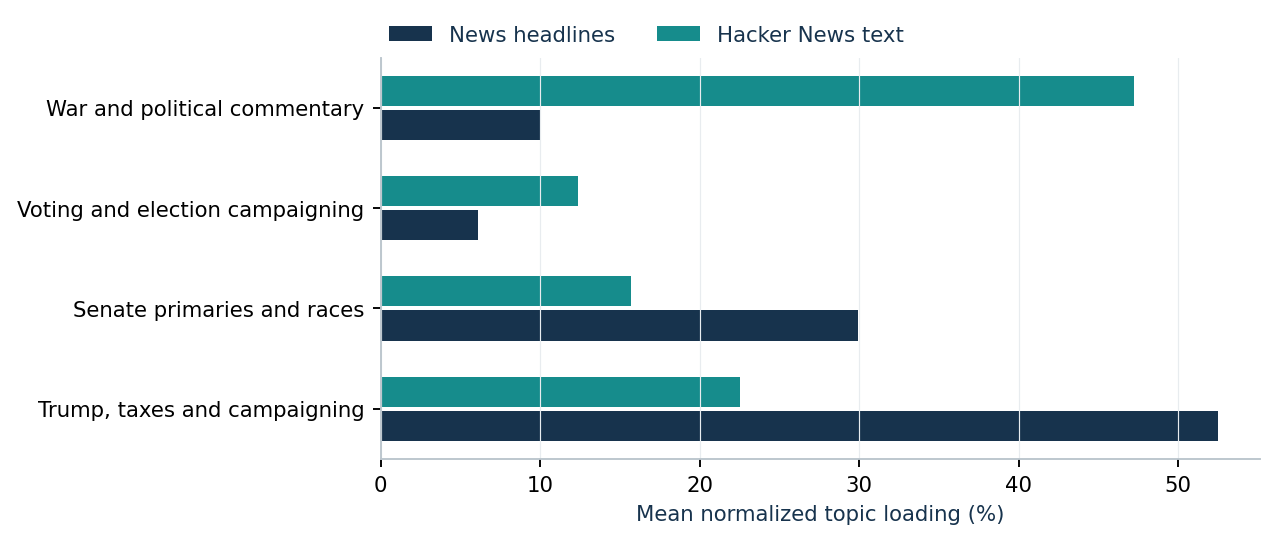

In [4]:
display(Image(filename=str(ROOT / 'outputs/topic_shares.png')))

NMF shares are mean normalized loadings, not calibrated topic probabilities or voter percentages. Labels summarize the top terms; clusters can mix policy and campaign language.

| Pew voter issue | Pew importance | News rule mentions | HN rule mentions |
| --- | --- | --- | --- |
| Economy | 84% | 4.3% | 29.0% |
| Future of democracy | 73% | 1.2% | 13.3% |
| Healthcare | 68% | 0.4% | 2.9% |
| Education | 62% | 0.0% | 2.2% |
| Immigration | 59% | 0.6% | 4.7% |
| Foreign policy | 57% | 5.3% | 22.6% |
| Energy policy | 54% | 1.2% | 11.5% |
| Violent crime | 52% | 0.2% | 2.2% |

Pew gives registered-voter shares calling each issue very important (Sept. 28–Oct. 4; published Oct. 8). Mention columns use overlapping rules: democracy includes ethics, energy includes climate, and crime includes guns. They are broader than those survey items, so their percentages are not directly equivalent. The October poll is interpretation only. The pre-window July poll already put economic issues first (29% open-ended), then ethics/reform (9%), immigration (7%), healthcare (5%) and foreign policy (4%).

In [5]:
print('topic_model_selection')
display(pd.read_csv(ROOT / 'outputs/topic_model_selection.csv'))

topic_model_selection


,k,training_npmi,seed_stability_cosine,smallest_mean_weight,min_topic_effective_support,max_topic_top_three_mass,training_documents,eligible,selected
0,4,0.0725,1.0000,0.1315,23.5684,0.2376,614,True,True
1,6,0.1782,0.7821,0.0723,16.7423,0.3626,614,False,False
2,8,0.2413,0.8787,0.0576,11.9417,0.4391,614,False,False


In [6]:
print('topic_summary')
display(pd.read_csv(ROOT / 'outputs/topic_summary.csv'))

topic_summary


,topic,label,top_terms,display_label,news_share,news_valence,social_share,social_valence
0,topic_0,war / party / going,"war, party, going, did, think, really, democracy, iran, know,...",War and political commentary,0.1000,-0.1479,0.4725,-0.4809
1,topic_1,november / vote / politics,"november, vote, politics, want, current, august, republicans,...",Voting and election campaigning,0.0612,-0.0920,0.1239,-0.4347
2,topic_2,federal / senate / democrats,"federal, senate, democrats, primary, senate primary, michigan...",Senate primaries and races,0.2993,-0.0456,0.1568,-0.4345
3,topic_3,trump / tax / capital,"trump, tax, capital, ahead, gop, republicans, president, dona...","Trump, taxes and campaigning",0.5250,-0.1879,0.2252,-0.4931


In [7]:
print('issue_summary')
display(pd.read_csv(ROOT / 'outputs/issue_summary.csv'))

issue_summary


,issue,source_type,n,share_pct,contextual_document_valence,sentence_vader_valence
0,economy,news,126,4.2668,-0.2754,-0.0747
1,economy,social,81,29.0323,-0.4480,-0.0403
2,democracy_ethics,news,34,1.1514,-0.4638,-0.1085
3,democracy_ethics,social,37,13.2616,-0.5088,-0.1109
4,healthcare,news,12,0.4064,0.0213,0.0144
5,healthcare,social,8,2.8674,-0.3566,0.2941
6,immigration,news,18,0.6095,-0.2717,-0.1545
7,immigration,social,13,4.6595,-0.5044,0.0057
8,foreign_policy,news,157,5.3166,-0.2913,-0.2483
9,foreign_policy,social,63,22.5806,-0.4965,-0.0891


## A sentiment module with explicit measurement limits

The primary score uses a pinned CardiffNLP Twitter RoBERTa model: probability of positive wording minus probability of negative wording. Headlines are scored as headlines; HN comments use their own text. Long records are split into token chunks and probabilities are averaged by token count, so no trailing text is discarded. This preserves one observation per record. The model’s 2018–2021 Twitter training domain differs from 2026 political headlines and HN.

For topic k, each medium’s daily valence is the NMF-loading-weighted mean of document scores. A topic needs at least 0.5 document-equivalents of loading within that medium and period. The combined index is one half news plus one half social; a missing component leaves it missing. The broad index averages all model-covered text with the same source balance. No missing text is assigned neutral sentiment. NMF loadings express mixture strength, not independent topic probabilities.

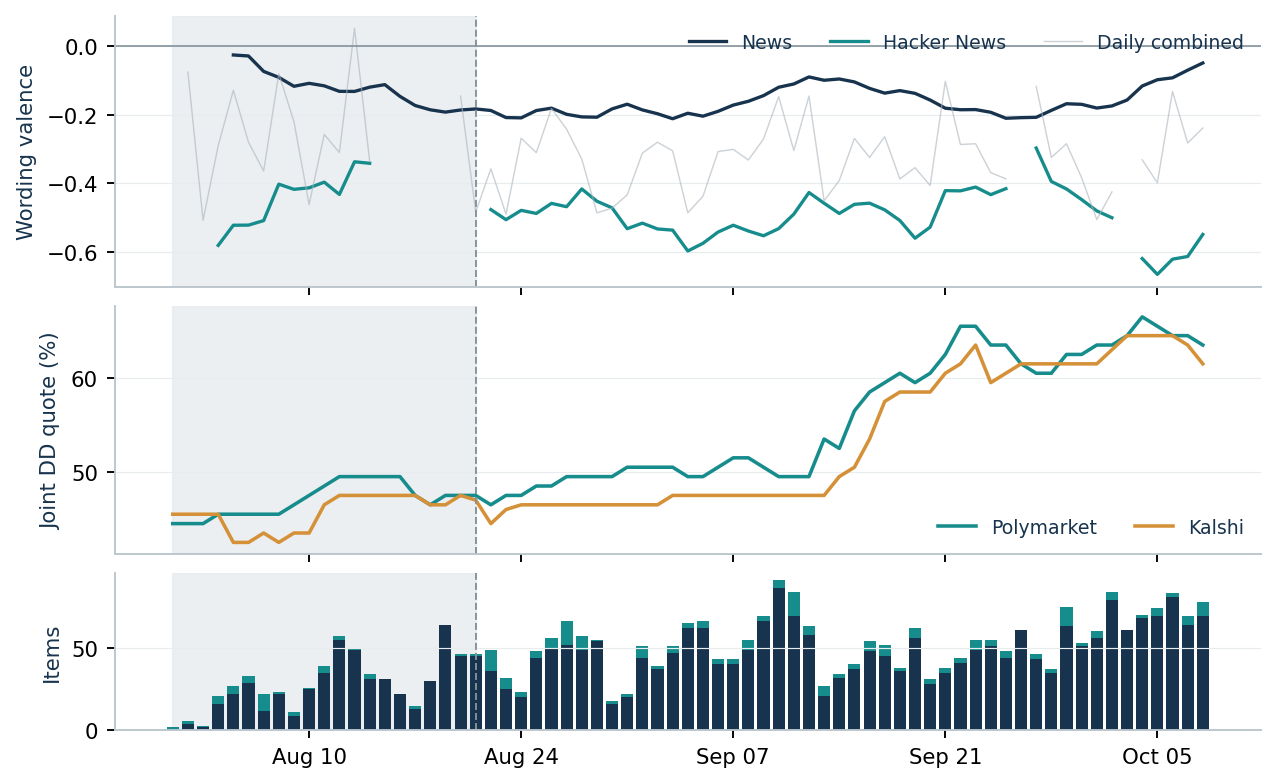

In [8]:
display(Image(filename=str(ROOT / 'outputs/sentiment_probability.png')))

Daily cutoffs are 16:00 New York. Source lines use trailing seven-day means for readability; all inference uses unsmoothed changes. Gray shading is the training window. Missing source days remain gaps.

RSS dates do not establish historical ingestion time, so headlines become eligible at the following New York midnight. HN uses creation time. Text enters the first eligible calendar close, or the next actual trading close for equities; weekend text accumulates into Monday. The final cutoff excludes later Oct. 8 text and next-day RSS availability. Current text and adjusted-price vintages may differ from what was visible historically.

A frozen, stratified 60-text AI-reference diagnostic was labeled before model scores were viewed. 52 records remain eligible after final timing/relevance screens. On the same records, contextual agreement is 41/52 (78.8%), compared with VADER 22/52 (42.3%). Contextual macro-F1 is 0.535; positive-class support is only 1, with 0 correctly classified. This development check informed model comparison; it is neither an untouched test nor independent human validation. Sarcasm, quotation and target ambiguity remain. Wording valence does not establish party support, issue approval or calibrated voter sentiment.

### sentiment review summary

Frozen aggregate diagnostic (AI reference; no independent human accuracy):

```json
{
  "classifier": "VADER 3.3.2 lexical/rule-based baseline",
  "n": 60,
  "agreements": 27,
  "ai_reference_agreement": 0.45,
  "ai_reference_macro_f1": 0.3974483378256963,
  "ambiguous_n": 29,
  "party_target_mismatch_n": 37,
  "unambiguous_n": 31,
  "unambiguous_agreement": 0.4838709677419355,
  "by_source": {
    "news": {
      "n": 30,
      "agreements": 11,
      "agreement": 0.36666666666666664
    },
    "social": {
      "n": 30,
      "agreements": 16,
      "agreement": 0.5333333333333333
    }
  },
  "by_split": {
    "evaluation": {
      "n": 40,
      "agreements": 18,
      "agreement": 0.45
    },
    "training": {
      "n": 20,
      "agreements": 9,
      "agreement": 0.45
    }
  },
  "retained_final_corpus_n": 52,
  "excluded_before_final_scoring_n": 8,
  "retained_final_corpus_agreements": 22,
  "retained_final_corpus_agreement": 0.4230769230769231,
  "focus_counts": {
    "direct": 43,
    "broader_election": 9,
    "incidental": 7,
    "other_election": 1
  },
  "interpretation": "AI-reference agreement diagnostic only, not human-validated accuracy. Labels were frozen blind to VADER scores, topics and market outcomes. Stratification and subjective reference labels prevent interpreting this as corpus or voter-population accuracy. The original diagnostic retains all frozen cases; final-corpus subset agreement is reported separately when subsequent timestamp filtering excludes cases."
}
```

### contextual review summary

Frozen aggregate diagnostic (AI reference; no independent human accuracy):

```json
{
  "n": 52,
  "agreements": 41,
  "ai_reference_agreement": 0.7884615384615384,
  "ai_reference_macro_f1": 0.5354938271604938,
  "contextual": {
    "n": 52,
    "agreements": 41,
    "ai_reference_agreement": 0.7884615384615384,
    "ai_reference_macro_f1": 0.5354938271604938
  },
  "vader": {
    "n": 52,
    "agreements": 22,
    "ai_reference_agreement": 0.4230769230769231,
    "ai_reference_macro_f1": 0.36077070859679555
  },
  "frozen_review_n": 60,
  "eligible_review_n": 52,
  "vader_baseline_field": "vader_class",
  "by_source": {
    "news": {
      "n": 29,
      "agreements": 26,
      "ai_reference_agreement": 0.896551724137931,
      "ai_reference_macro_f1": 0.5957918050941307
    },
    "social": {
      "n": 23,
      "agreements": 15,
      "ai_reference_agreement": 0.6521739130434783,
      "ai_reference_macro_f1": 0.376114081996435
    }
  },
  "by_split": {
    "evaluation": {
      "n": 35,
      "agreements": 29,
      "ai_reference_agreement": 0.8285714285714286,
      "ai_reference_macro_f1": 0.5602240896358542
    },
    "training": {
      "n": 17,
      "agreements": 12,
      "ai_reference_agreement": 0.7058823529411765,
      "ai_reference_macro_f1": 0.48370927318295737
    }
  },
  "confusion_order": [
    "negative",
    "neutral",
    "positive"
  ],
  "contextual_confusion": [
    [
      19,
      6,
      0
    ],
    [
      3,
      22,
      1
    ],
    [
      1,
      0,
      0
    ]
  ],
  "vader_confusion": [
    [
      14,
      4,
      7
    ],
    [
      7,
      7,
      12
    ],
    [
      0,
      0,
      1
    ]
  ],
  "labels_sha256": "f21eff97a971834ffa5877b48479c04b96d66837c7f528a0a72809ca23cbdf54",
  "model_revision": "3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7",
  "model_fitted_on_review": false,
  "interpretation": "Agreement with the final-corpus-eligible subset of 60 frozen AI-reference development labels only; excluded labels remain frozen and are not replaced. Not independent human-validated accuracy, representative corpus accuracy, political stance validation, or calibrated probability. This diagnostic was consulted for model comparison and cannot serve as an untouched final test set.",
  "unambiguous": {
    "n": 27,
    "agreements": 25,
    "ai_reference_agreement": 0.9259259259259259,
    "ai_reference_macro_f1": 0.6172161172161172
  },
  "excluded_review_n": 8
}
```

## Association with sweep prices and market returns

Polymarket’s YES asset directly prices Democratic House and Senate control. Kalshi’s DD combination is also joint, using the midpoint of closing hourly YES bid/ask quotes. The latest observation at or before 16:00 is used; observations older than 24 hours are missing. Polymarket resolves control following the November election, while Kalshi refers to February 2027. Settlement rules, spreads, liquidity and fees can all contribute to their difference. Quotes are market-implied prices, not a validated statistical forecast.

Primary tests use changes in wording and changes in contract prices, or daily adjusted equity returns. Calendar days are used for contracts; actual cash sessions are used for stocks. Lag 0 is contemporaneous association; lag 1 pairs the prior period’s sentiment change with today’s outcome. Differences and lags are created before incomplete pairs are deleted. Levels are reported separately because common trends can generate misleading correlations.

| Broad-index outcome | Lag | n | Pearson r | 95% block interval | Holm p |
| --- | --- | --- | --- | --- | --- |
| Kalshi Δquote | 0 | 44 | 0.10 | [-0.12, 0.30] | 1.000 |
| Kalshi Δquote | 1 | 44 | 0.07 | [-0.19, 0.37] | 1.000 |
| Polymarket Δquote | 0 | 44 | -0.18 | [-0.45, 0.14] | 1.000 |
| Polymarket Δquote | 1 | 44 | 0.43 | [0.09, 0.62] | 0.106 |
| Five-stock minus SPY | 0 | 33 | -0.05 | [-0.38, 0.30] | 1.000 |
| Five-stock minus SPY | 1 | 33 | 0.08 | [-0.34, 0.48] | 1.000 |
| Signed beta-adjusted | 0 | 33 | 0.43 | [0.21, 0.64] | 0.148 |
| Signed beta-adjusted | 1 | 33 | -0.17 | [-0.45, 0.06] | 1.000 |

| NMF topic: same-day Polymarket change | n | r | Holm p |
| --- | --- | --- | --- |
| War and political commentary | 41 | -0.06 | 1.000 |
| Voting and election campaigning | 1 | — | — |
| Senate primaries and races | 12 | -0.41 | 1.000 |
| Trump, taxes and campaigning | 23 | -0.52 | 0.487 |

OLS slope tests use a three-period Bartlett HAC covariance on the full time grid, including missing-period positions. Pointwise correlation intervals use 999 circular, five-period block resamples. Holm correction covers the fixed 40-test core family; insufficient-sample cases remain untested and count conservatively in that family. Intervals are not simultaneous, and a short, partly missing series limits both HAC and bootstrap reliability.

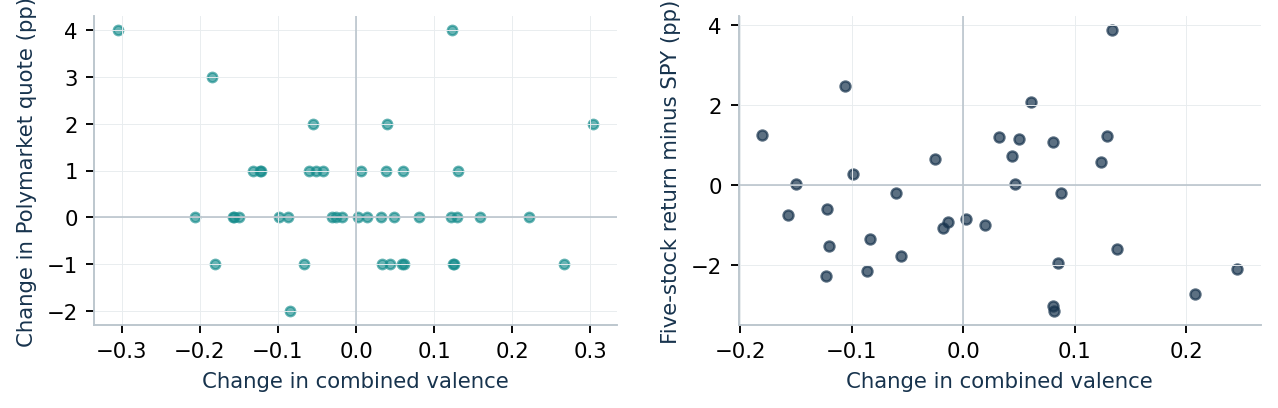

In [9]:
display(Image(filename=str(ROOT / 'outputs/association_scatter.png')))

Assessment period only. Contract changes are percentage points; stock adjustment is the daily basket return less SPY. Scatterplots show the raw association without selecting a favorable trend line.

Named policy issues are also measured with an explicit dictionary, separately from NMF: contextual scores on matching records, plus sentence-restricted VADER as a scope sensitivity. Their news-only and equal-medium contract/equity results form a separate exploratory family. Whole-record context can mix attitudes toward several issues. Sparse HN issue coverage often prevents daily topic inference. The notebook reports those sample sizes and tests, together with level correlations, source sensitivities, individual equities and direct quote-change/equity associations.

In [10]:
print('correlations')
display(pd.read_csv(ROOT / 'outputs/correlations.csv'))

correlations


,frequency,index,target,lag,hypothesis,n,pearson_r,spearman_r,hac_slope,hac_p,block_ci_low,block_ci_high,holm_p
0,calendar,index_all,kalshi_probability,0,contemporaneous association,44,0.1019,0.1008,0.0101,0.3499,-0.1192,0.3012,1.0000
1,calendar,index_all,kalshi_probability,1,lagged association,44,0.0663,0.0154,0.0062,0.6652,-0.1891,0.3656,1.0000
2,calendar,index_all,polymarket_probability,0,contemporaneous association,44,-0.1762,-0.1504,-0.0174,0.2624,-0.4508,0.1384,1.0000
3,calendar,index_all,polymarket_probability,1,lagged association,44,0.4320,0.4338,0.0409,0.0027,0.0868,0.6222,0.1061
4,calendar,index_topic_0,kalshi_probability,0,contemporaneous association,41,0.0617,0.0265,0.0045,0.4567,-0.1556,0.2102,1.0000
5,calendar,index_topic_0,kalshi_probability,1,lagged association,40,0.0385,0.0143,0.0028,0.6978,-0.1726,0.1922,1.0000
6,calendar,index_topic_0,polymarket_probability,0,contemporaneous association,41,-0.0646,-0.0490,-0.0048,0.7248,-0.4114,0.2774,1.0000
7,calendar,index_topic_0,polymarket_probability,1,lagged association,40,0.2926,0.2933,0.0227,0.2096,-0.1547,0.5909,1.0000
8,calendar,index_topic_1,kalshi_probability,0,contemporaneous association,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,calendar,index_topic_1,kalshi_probability,1,lagged association,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
print('flagged_diagnostics')
display(pd.read_csv(ROOT / 'outputs/flagged_diagnostics.csv'))

flagged_diagnostics


,index,target,diagnostic,n,pearson_r,hac_p,ordinary_iid_p,leave_one_r_min,leave_one_r_max
0,index_topic_3,signed_beta_adjusted,HAC_lags_1,28,0.3599,0.0013,NaN,NaN,NaN
1,index_topic_3,signed_beta_adjusted,HAC_lags_3,28,0.3599,0.0006,NaN,NaN,NaN
2,index_topic_3,signed_beta_adjusted,HAC_lags_5,28,0.3599,0.0003,NaN,NaN,NaN
3,index_topic_3,signed_beta_adjusted,ordinary_iid_and_leave_one_pair_out,28,0.3599,NaN,0.06,0.3052,0.4595


In [12]:
print('level_correlations')
display(pd.read_csv(ROOT / 'outputs/level_correlations.csv'))

level_correlations


,index,target,n,pearson_r,warning
0,index_all,kalshi_probability,46,0.1203,Levels can be spurious; primary tests use changes.
1,index_all,polymarket_probability,46,0.0850,Levels can be spurious; primary tests use changes.


In [13]:
print('sensitivities')
display(pd.read_csv(ROOT / 'outputs/sensitivities.csv'))

sensitivities


,specification,target,n,pearson_r,spearman_r,hac_slope,hac_p,block_ci_low,block_ci_high
0,equal_author_outlet,kalshi_probability,44,0.1075,0.0753,0.0106,0.2840,NaN,NaN
1,equal_author_outlet,polymarket_probability,44,-0.2039,-0.1872,-0.0200,0.2054,NaN,NaN
2,vader_lexical,kalshi_probability,44,0.0503,0.1087,0.0031,0.6607,NaN,NaN
3,vader_lexical,polymarket_probability,44,-0.0681,0.0172,-0.0042,0.6596,NaN,NaN
4,polarity_balance,kalshi_probability,44,0.0638,0.0561,0.0168,0.5896,NaN,NaN
5,polarity_balance,polymarket_probability,44,0.0192,0.0480,0.0050,0.8888,NaN,NaN
6,news_only,kalshi_probability,48,0.1508,0.2033,0.0200,0.2425,NaN,NaN
7,news_only,polymarket_probability,48,0.0537,0.0987,0.0075,0.6171,NaN,NaN
8,social_only,kalshi_probability,44,0.0489,0.0309,0.0023,0.5445,NaN,NaN
9,social_only,polymarket_probability,44,-0.1673,-0.1648,-0.0078,0.2427,NaN,NaN


In [14]:
print('issue_correlations')
display(pd.read_csv(ROOT / 'outputs/issue_correlations.csv'))

issue_correlations


,issue,specification,target,n,pearson_r,spearman_r,hac_slope,hac_p,block_ci_low,block_ci_high,holm_p
0,economy,equal_media,polymarket_probability,13,-0.0496,-0.1082,-0.0038,0.8366,NaN,NaN,1.0
1,economy,news_only,polymarket_probability,31,-0.0101,-0.0404,-0.0004,0.9398,NaN,NaN,1.0
2,economy,equal_media,kalshi_probability,13,0.2199,0.0872,0.0097,0.4907,NaN,NaN,1.0
3,economy,news_only,kalshi_probability,31,0.3502,0.3294,0.0131,0.1434,NaN,NaN,1.0
4,economy,equal_media,long_only_minus_spy,12,0.1530,0.0979,0.0112,0.5139,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...
85,abortion,news_only,long_only_minus_spy,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
86,abortion,equal_media,signed_beta_adjusted,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
87,abortion,news_only,signed_beta_adjusted,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
88,abortion,sentence_vader_news,polymarket_probability,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
print('probability_equity_associations')
display(pd.read_csv(ROOT / 'outputs/probability_equity_associations.csv'))

probability_equity_associations


,probability,equity,n,pearson_r,spearman_r,hac_slope,hac_p,block_ci_low,block_ci_high
0,kalshi_probability,long_only_minus_spy,33,0.0028,-0.0642,0.0033,0.9783,NaN,NaN
1,kalshi_probability,signed_beta_adjusted,33,0.2645,-0.0107,0.3340,0.2783,NaN,NaN
2,polymarket_probability,long_only_minus_spy,33,0.2397,0.1536,0.2679,0.1739,NaN,NaN
3,polymarket_probability,signed_beta_adjusted,33,0.2280,0.2062,0.2713,0.2966,NaN,NaN


## Equity scenarios and market-adjusted performance

| Equity | Sweep hypothesis | Policy channel and qualification |
| --- | --- | --- |
| FSLR | Positive | Domestic solar manufacturing and Section 45X credits; trade policy can offset this channel. |
| ENPH / RUN | Positive | Residential solar/storage demand and financing; a sweep cannot itself restore expired credits. |
| GEO / CXW | Negative | Detention appropriations and contract growth; multiyear funding limits immediate reversal. |
| UNH | Ambiguous | Public-program funding versus insurer regulation; diagnostic, outside the five-stock basket. |

Signs follow company 10-Ks and Public Law 119-21, fixed before this project’s return inspection but after the study period. A congressional sweep faces presidential veto power, Senate procedure and existing funding. Residential Section 25D eligibility ended after 2025; CXW reports detention funding available through September 2029. Neither provision automatically reverses after the election.

The long-only basket holds five stocks at 20% daily target weights. The directional basket is 50% gross long solar (one sixth each) and 50% gross short detention (minus one quarter each): 100% gross, zero net dollars. SPY subtraction cancels in this dollar-neutral basket; its additional adjustment uses constituent SPY betas frozen from 62 May–July sessions. Solar/TAN, detention/IWM and UNH/XLV differences provide diagnostics. IWM is a size proxy, not a detention-sector hedge.

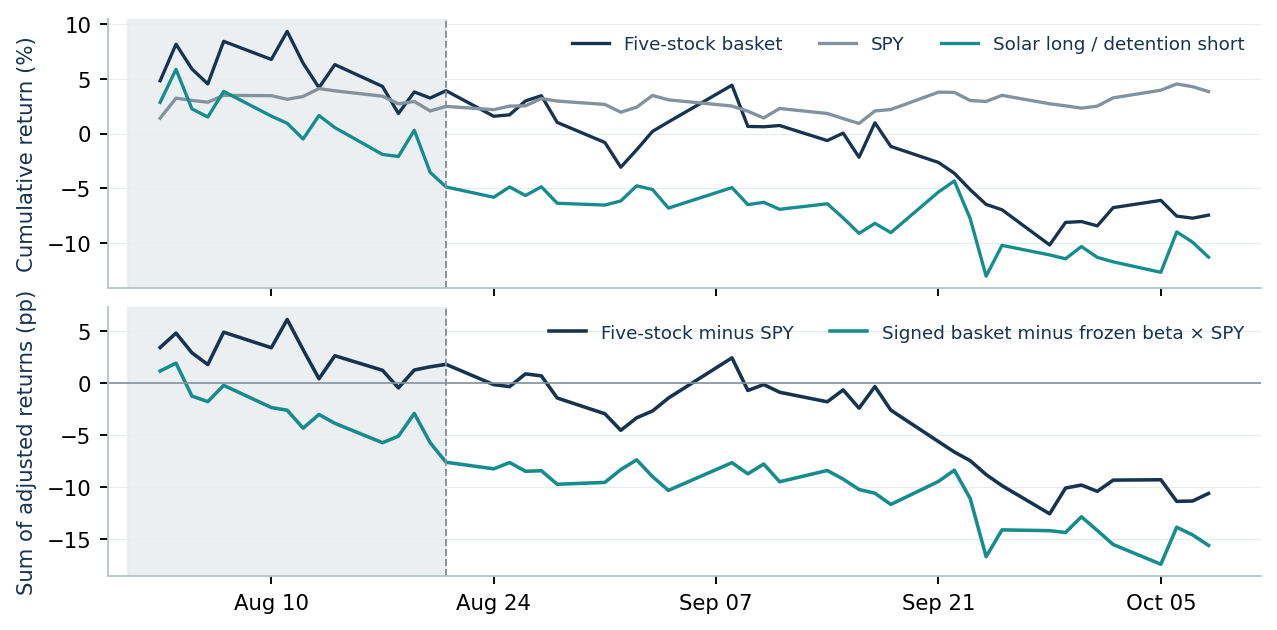

In [16]:
display(Image(filename=str(ROOT / 'outputs/basket_performance.png')))

Full Aug. 1–Oct. 8 window, using the July 31 prior close. Lower-panel values are sums of daily return differences, not compounded alpha. The signed strategy omits borrow, financing, fees and trading costs.

| Equity | Assessment return | Sum: return − SPY | Sum: return − βSPY |
| --- | --- | --- | --- |
| CXW | -3.82% | -3.79 pp | -2.84 pp |
| ENPH | -14.76% | -16.11 pp | -20.15 pp |
| FSLR | -16.53% | -17.83 pp | -20.11 pp |
| GEO | -5.35% | -5.84 pp | -5.63 pp |
| RUN | -17.14% | -18.59 pp | -20.46 pp |
| UNH | -4.33% | -5.54 pp | -4.24 pp |

The table covers Aug. 24–Oct. 8 only; the chart covers the entire study. The broad-index same-day correlation is -0.05 with the five-stock SPY spread and 0.43 with the signed beta adjustment. Neither the raw path nor a positive sample correlation identifies election causality. Rates, energy prices, company earnings, contracts and sector news offer competing explanations.

In [17]:
print('equity_performance')
display(pd.read_csv(ROOT / 'outputs/equity_performance.csv'))

equity_performance


,ticker,test_n,total_return_pct,sum_spy_adjusted_pct,sum_beta_adjusted_pct,sum_sector_adjusted_pct
0,CXW,33,-3.8224,-3.7909,-2.8417,4.9836
1,ENPH,33,-14.7630,-16.1105,-20.1469,-2.3781
2,FSLR,33,-16.5344,-17.8282,-20.1105,-4.0958
3,GEO,33,-5.3500,-5.8364,-5.6279,2.9382
4,RUN,33,-17.1397,-18.5900,-20.4555,-4.8576
5,UNH,33,-4.3259,-5.5405,-4.2414,-0.8883


In [18]:
print('individual_equity_correlations')
display(pd.read_csv(ROOT / 'outputs/individual_equity_correlations.csv'))

individual_equity_correlations


,ticker,adjustment,n,pearson_r,spearman_r,hac_slope,hac_p,block_ci_low,block_ci_high,holm_p
0,CXW,market_adjusted_return_pct,33,-0.2626,-0.1521,-0.0768,0.0556,NaN,NaN,0.6116
1,CXW,beta_adjusted_return_pct,33,-0.2783,-0.2313,-0.0778,0.0355,NaN,NaN,0.5450
2,CXW,sector_adjusted_return_pct,33,-0.2590,-0.1658,-0.0729,0.0469,NaN,NaN,0.6050
3,ENPH,market_adjusted_return_pct,33,0.1072,0.1053,0.0255,0.6030,NaN,NaN,1.0000
4,ENPH,beta_adjusted_return_pct,33,0.1087,0.1223,0.0298,0.5714,NaN,NaN,1.0000
5,ENPH,sector_adjusted_return_pct,33,-0.0167,-0.0191,-0.0030,0.9348,NaN,NaN,1.0000
6,FSLR,market_adjusted_return_pct,33,0.2424,0.2082,0.0627,0.0752,NaN,NaN,0.6768
7,FSLR,beta_adjusted_return_pct,33,0.2683,0.1852,0.0651,0.0583,NaN,NaN,0.6116
8,FSLR,sector_adjusted_return_pct,33,0.1896,0.0705,0.0341,0.1978,NaN,NaN,1.0000
9,GEO,market_adjusted_return_pct,33,-0.4121,-0.2627,-0.0988,0.0341,NaN,NaN,0.5450


## Conclusions, investment use and reproducibility

I draw three conclusions. First, economic conditions and affordability are the clearest shared voter concern, with democracy and healthcare also prominent in the October importance ratings. Second, election-search topic frequencies are strongly shaped by campaigning and source selection, so they cannot replace survey evidence. Third, political wording, prediction-contract quotes and policy-exposed equity returns are different measurements. Their short-run association is too unstable and sample-dependent to treat as a causal or dependable trading signal.

1 of 40 core associations survives Holm correction: Trump, taxes and campaigning and signed beta-adjusted basket, lag 0: r=0.36, n=28, adjusted p=0.023. Independent confirmation is needed. For the flagged contemporaneous result, an ordinary IID test gives p=0.060, while leave-one-pair-out r ranges from 0.31 to 0.46. Covariance assumptions matter, and contemporaneous association does not establish a forecast. Any nominally interesting topic, lag or individual equity remains exploratory. The model was selected without return information, but collection screens, topic diagnostics and the sentiment-method comparison were developed retrospectively. The assessment period therefore evaluates a frozen text model; it is not an untouched prospective trading test. The election outcome itself is still unobserved.

My practical investment suggestion is a watchlist with explicit triggers: monitor affordability and healthcare discussion, both joint-control contracts, solar-credit legislation, detention appropriations and company guidance. FSLR/ENPH/RUN could benefit from supportive solar policy, while GEO/CXW could face slower expansion under tighter oversight. I would require a separately labeled human validation sample and forward testing before using this index to size positions. A hypothetical long-solar/short-detention scenario basket helps stress-test exposure, but the observed losses and omitted costs do not support recommending it as a profitable trade.

The main limits are ranked and capped RSS discovery, a small technology-community social sample, unverified voter residence, near-duplicate paraphrases, uncertain historical text vintages and imperfect sentiment targets. Guardian access failed (401); Reddit and Bluesky failed (403). Broad GDELT requests were rate-limited (429); five records from a limited access probe are kept outside the study. No population-level voter sentiment, independent human accuracy, causal election effect or profitable out-of-sample strategy is claimed.

The [GitHub repository](https://github.com/ph2606/FRE-GY-7871A-Assignment5) contains reusable acquisition, text modeling, sentiment, analysis and validation code; exact dependency pins; an executed notebook with aggregate outputs; and a truthful AI-use disclosure. The separate PDF is the report. Raw payloads, source texts, label audits, prices and derived datasets remain local and are excluded from Git. The snapshot manifest records local hashes. Fresh API downloads reproduce the method, while mutable feeds and prices may change the snapshot.

Selected primary sources: [Pew October issue priorities](https://www.pewresearch.org/politics/2026/10/08/economy-ranks-as-top-issue-in-midterms-for-all-voters-but-partisans-differ-over-the-importance-of-other-issues/); [Pew July open-ended priorities](https://www.pewresearch.org/politics/2026/07/23/as-the-2026-midterms-approach-economy-is-front-and-center/); [HN Algolia API](https://hn.algolia.com/api); [scikit-learn NMF](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html); [CardiffNLP model card](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest); [VADER authors’ implementation](https://github.com/cjhutto/vaderSentiment); [Polymarket event](https://polymarket.com/event/balance-of-power-2026-midterms); [Kalshi API](https://docs.kalshi.com/api-reference/market/get-market-candlesticks); [Public Law 119-21](https://www.govinfo.gov/content/pkg/PLAW-119publ21/html/PLAW-119publ21.htm).

Company evidence: [First Solar 2025 annual report](https://s202.q4cdn.com/499595574/files/doc_financials/2025/ar/FSLR-2025-Annual-Report-web.pdf); [Enphase 2025 10-K](https://www.sec.gov/Archives/edgar/data/1463101/000146310126000013/enph-20251231.htm); [Sunrun 2025 10-K](https://investors.sunrun.com/filings-financials/sec-filings/content/0001628280-26-012289/run-20251231.htm); [GEO 2025 10-K](https://www.sec.gov/Archives/edgar/data/923796/000119312526071747/geo-20251231.htm); [CoreCivic 2025 10-K](https://ir.corecivic.com/static-files/3f95f305-eeb0-4aba-abbd-d1db10deca6a); [UnitedHealth 2025 10-K](https://www.unitedhealthgroup.com/content/dam/UHG/PDF/investors/2025/UNH-Q4-2025-Form-10-K.pdf).

## Measurement, model and timing audit

The checks below audit implementation and acquired-record alignment. They do not establish voter identity, sentiment accuracy or causal effects. Detailed labels and texts remain local. The October poll never supplies historical index weights.

In [19]:
collection = json.loads((ROOT / 'outputs/text_collection_summary.json').read_text())
print(json.dumps(collection, indent=2))
print('Source collection counts precede the final analysis availability cutoff.')

{
  "requested_start_et": "2026-08-01T00:00:00-04:00",
  "requested_end_exclusive_et": "2026-10-09T00:00:00-04:00",
  "collected_at": "2026-10-09T16:43:43.984018+00:00",
  "cache_only_run": true,
  "news_queries": {
    "midterms": "(midterm OR \"congressional election\") (US OR \"United States\" OR Democrat OR Republican OR Trump)",
    "congress": "(House OR Senate) (election OR voters) (Democrats OR Republicans)"
  },
  "hn_queries": [
    "midterm",
    "congressional election",
    "Senate election",
    "House election",
    "election",
    "voter",
    "ballot"
  ],
  "unique_candidates": 9099,
  "included": 3326,
  "by_source_type": {
    "news": 3042,
    "social": 284
  },
  "by_provider": {
    "Google News RSS": 3042,
    "HN Algolia": 284
  },
  "exclusions": {
    "": 3326,
    "no explicit US political context": 2421,
    "no explicit dated-election or congressional-midterm context": 1392,
    "no explicit election context": 1332,
    "duplicate normalized own text": 473

In [20]:
assert scored.id.is_unique
assert scored.available_at.max() <= pd.Timestamp('2026-10-08T20:00:00Z')
assert market.index.is_unique and calendar.index.is_unique
assert market[['long_only_minus_spy','signed_beta_adjusted']].notna().all().all()
assert scored.token_truncation.eq(False).all()
assert scored.discarded_tokens.eq(0).all()
method = json.loads((ROOT / 'outputs/text_method.json').read_text())
print(json.dumps(method, indent=2))
print('No post-cutoff text, duplicate IDs, truncated text or incomplete basket returns entered the submitted results.')

{
  "training_end": "2026-08-21 16:00:00-04:00",
  "training_available_n": 614,
  "fitted_balanced_n": 614,
  "k": 4,
  "source_balance": "All capped training documents retained; sqrt(N/(medium_count*n_medium)) row scaling balances the NMF objective. Vocabulary IDF uses all training documents.",
  "stop_words": [
    "2026",
    "2027",
    "a",
    "about",
    "above",
    "across",
    "after",
    "afterwards",
    "again",
    "against",
    "all",
    "almost",
    "alone",
    "along",
    "already",
    "also",
    "although",
    "always",
    "am",
    "among",
    "amongst",
    "amoungst",
    "amount",
    "amp",
    "an",
    "and",
    "another",
    "any",
    "anyhow",
    "anyone",
    "anything",
    "anyway",
    "anywhere",
    "are",
    "around",
    "as",
    "at",
    "back",
    "be",
    "became",
    "because",
    "become",
    "becomes",
    "becoming",
    "been",
    "before",
    "beforehand",
    "behind",
    "being",
    "below",
    "beside",
    "b

## Reproduction boundary

A fresh clone must run acquisition and contextual model download before executing this notebook. APIs can revise rankings, text and adjusted prices; a fresh run reproduces the method rather than guaranteeing the exact saved snapshot. Local SHA256 manifests bind this submission to its actual acquired inputs. All synthetic data are confined to software tests. No trade or institutional submission was made.